# Choice of DFU: comparing polarization metrics on synthetic distributions

Six metrics, all computed from the **counts per rating** on an ordinal 1–5 scale (1 = civil, 5 = toxic):

1. **DFU**: Distance From Unimodality (Pavlopoulos & Likas, 2023), on relative frequencies. 0 for any unimodal distribution.
2. **nDFU**: normalized DFU (Pavlopoulos & Likas, 2024): DFU divided by the height of the mode.
3. **A**: van der Eijk's agreement (van der Eijk, 2001), in [-1, 1]. 1 = full agreement, 0 = uniform, -1 = split between the extremes.
4. **Agr.**: pairwise agreement, the probability that two random annotators give the same rating.
5. **Bal.**: balance between the two halves of the scale, 1 - |low - high| / (low + high), midpoint excluded.
6. **BC**: Sarle's bimodality coefficient (Pfister et al., 2013). Values above 0.555 suggest bimodality.

In [1]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Synthetic distributions
Counts of annotators per rating 1..5. Change them here if your original data differs.

In [2]:
DISTRIBUTIONS = {
    "Sym. Uni.":  [1, 4, 7, 4, 1],
    "Skew. Uni.": [0, 1, 3, 6, 7],
    "Bal. Bi.":   [6, 2, 0, 2, 6],
    "Imbal. Bi.": [7, 2, 0, 1, 3],
    "Trimodal":   [5, 0, 5, 0, 5],
}

## Metrics

In [7]:
def dfu(counts, normalized=False):
    """Distance From Unimodality: the largest rise met when walking away from the mode.
    0 for any unimodal distribution. Computed on relative frequencies."""
    h = np.asarray(counts, dtype=float)
    h = h / h.sum()
    pos_max = int(np.argmax(h))
    max_diff = 0.0
    for i in range(pos_max, len(h) - 1):      # walk right from the mode
        max_diff = max(max_diff, h[i + 1] - h[i])
    for i in range(pos_max, 0, -1):           # walk left from the mode
        max_diff = max(max_diff, h[i - 1] - h[i])
    return max_diff / h[pos_max] if normalized else max_diff


def ndfu(counts):
    return dfu(counts, normalized=True)


def _eijk_layer(pattern):
    K, S = len(pattern), sum(pattern)
    if S == 1:
        return 1.0
    if S == K:
        return 0.0
    TU = TDU = 0
    for i, j, k in combinations(range(K), 3):
        t = (pattern[i], pattern[j], pattern[k])
        if t in [(1, 1, 0), (0, 1, 1)]:
            TU += 1
        elif t == (1, 0, 1):
            TDU += 1
    U = 1.0 if TU + TDU == 0 else ((K - 2) * TU - (K - 1) * TDU) / ((K - 2) * (TU + TDU))
    return U * (1 - (S - 1) / (K - 1))


def van_der_eijk(counts):
    """van der Eijk's agreement A: 1 = full agreement, 0 = uniform, -1 = split between the extremes."""
    f, total, acc = list(counts), 0, 0.0
    while any(f):
        m = min(x for x in f if x > 0)
        pattern = [1 if x > 0 else 0 for x in f]
        acc += m * _eijk_layer(pattern)
        total += m
        f = [x - m if x > 0 else 0 for x in f]
    return acc / total


def pairwise_agreement(counts):
    """Probability that two randomly chosen (different) annotators gave the same rating."""
    n = np.asarray(counts, dtype=float)
    N = n.sum()
    return float((n * (n - 1)).sum() / (N * (N - 1)))


def balance(counts):
    """How evenly ratings split between the two halves of the scale (midpoint excluded)."""
    n = np.asarray(counts, dtype=float)
    K = len(n)
    low, high = n[: K // 2].sum(), n[(K + 1) // 2:].sum()
    if low + high == 0:
        return 0.0
    return float(1 - abs(low - high) / (low + high))


def bimodality_coefficient(counts):
    """Sarle's bimodality coefficient with bias-corrected skewness and excess kurtosis."""
    ratings = np.repeat(np.arange(1, len(counts) + 1), counts).astype(float)
    n = len(ratings)
    m = ratings.mean()
    m2 = ((ratings - m) ** 2).mean()
    m3 = ((ratings - m) ** 3).mean()
    m4 = ((ratings - m) ** 4).mean()
    g1 = m3 / m2 ** 1.5                                      # population skewness
    g2 = m4 / m2 ** 2 - 3                                    # population excess kurtosis
    G1 = g1 * np.sqrt(n * (n - 1)) / (n - 2)                 # sample skewness
    G2 = ((n + 1) * g2 + 6) * (n - 1) / ((n - 2) * (n - 3))  # sample excess kurtosis
    return float((G1 ** 2 + 1) / (G2 + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3))))


METRICS = {
    "DFU": dfu,
    "nDFU": ndfu,
    "van der Eijk": van_der_eijk,
    "Agr.": pairwise_agreement,
    "Bal.": balance,
    "BC": bimodality_coefficient,
}

## Sanity checks for van der Eijk's A

In [8]:
assert abs(van_der_eijk([5, 0, 0, 0, 5]) + 1) < 1e-9   # split between the extremes -> -1
assert abs(van_der_eijk([0, 0, 5, 0, 0]) - 1) < 1e-9   # full agreement -> 1
assert abs(van_der_eijk([2, 2, 2, 2, 2])) < 1e-9       # uniform -> 0
assert dfu([1, 4, 7, 4, 1]) == 0                        # unimodal -> DFU = 0
print("all checks passed")

all checks passed


## Results

In [9]:
rows = {name: {m: f(c) for m, f in METRICS.items()} for name, c in DISTRIBUTIONS.items()}
results = pd.DataFrame(rows).T.round(2)
results

,DFU,nDFU,van der Eijk,Agr.,Bal.,BC
Sym. Uni.,0.00,0.00,0.64,0.24,1.00,0.27
Skew. Uni.,0.00,0.00,0.64,0.29,0.14,0.45
Bal. Bi.,0.25,0.67,-0.71,0.27,1.00,0.62
Imbal. Bi.,0.15,0.29,0.37,0.32,0.62,0.65
Trimodal,0.33,1.00,-0.28,0.29,1.00,0.46


## LaTeX rows to paste into the table

In [6]:
print(" & ".join(["Distribution"] + [f"\\ac{{{c}}}" if "DFU" in c else ("$A$" if c == "A" else c) for c in results.columns]) + " \\\\")
for name, r in results.iterrows():
    cells = " & ".join(f"${v:+.2f}$" if col == "A" else f"{v:.2f}" for col, v in r.items())
    print(f"{name} & {cells} \\\\")

Distribution & \ac{DFU} & \ac{nDFU} & $A$ & Agr. & Bal. & BC \\
Sym. Uni. & 0.00 & 0.00 & $+0.64$ & 0.24 & 1.00 & 0.27 \\
Skew. Uni. & 0.00 & 0.00 & $+0.64$ & 0.29 & 0.14 & 0.45 \\
Bal. Bi. & 0.25 & 0.67 & $-0.71$ & 0.27 & 1.00 & 0.62 \\
Imbal. Bi. & 0.15 & 0.29 & $+0.37$ & 0.32 & 0.62 & 0.65 \\
Trimodal & 0.33 & 1.00 & $-0.28$ & 0.29 & 1.00 & 0.46 \\


## Figure of the distributions

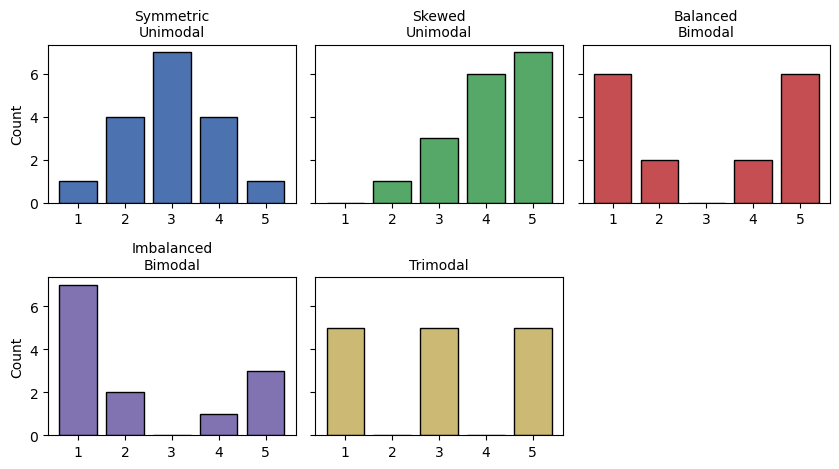

In [12]:
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
titles = ["Symmetric\nUnimodal", "Skewed\nUnimodal", "Balanced\nBimodal", "Imbalanced\nBimodal", "Trimodal"]
fig, axes = plt.subplots(2, 3, figsize=(8.5, 4.8), sharey=True)
for ax, (name, counts), color, title in zip(axes.flat, DISTRIBUTIONS.items(), colors, titles):
    ax.bar(range(1, 6), counts, color=color, edgecolor="black")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(1, 6))
axes[0, 0].set_ylabel("Count")
axes[1, 0].set_ylabel("Count")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("poldistrs.pdf", bbox_inches="tight")
plt.show()